DOG vs CAT classification project

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings('ignore')

In [15]:
import tensorflow as tf
from tensorflow import keras
from keras import Sequential
from keras.layers import Dense, Conv2D, MaxPooling2D, Flatten, Dropout, BatchNormalization

In [5]:
# generators
train_ds = keras.utils.image_dataset_from_directory(
    directory = "/mnt/c/Users/ASUS/OneDrive/Desktop/Deep-Learning/CNN/DOG VS CAT classification/train",
    labels = 'inferred',
    label_mode = 'int',
    batch_size = 16, 
    image_size = (256, 256)
)

Found 20000 files belonging to 2 classes.


In [6]:
validation_ds = keras.utils.image_dataset_from_directory(
    directory = "/mnt/c/Users/ASUS/OneDrive/Desktop/Deep-Learning/CNN/DOG VS CAT classification/test",
    labels = 'inferred',
    label_mode = 'int',
    batch_size = 32, 
    image_size = (256, 256)
)

Found 4981 files belonging to 2 classes.


In [7]:
# normalize 
def process(image, label) :
    image = tf.cast(image/255., tf.float32)
    return image, label

train_ds = train_ds.map(process)
validation_ds = validation_ds.map(process)

In [16]:
# Create CNN
model = Sequential()

model.add(Conv2D(32, kernel_size=(3,3), padding= 'valid', activation= 'relu', input_shape = (256, 256, 3)))
model.add(BatchNormalization())
model.add(MaxPooling2D(pool_size=(2,2), strides=2, padding= 'valid'))

model.add(Conv2D(64, kernel_size=(3,3), padding= 'valid', activation= 'relu'))
model.add(BatchNormalization())
model.add(MaxPooling2D(pool_size=(2,2), strides=2, padding= 'valid'))

model.add(Conv2D(32, kernel_size=(3,3), padding= 'valid', activation= 'relu'))
model.add(BatchNormalization())
model.add(MaxPooling2D(pool_size=(2,2), strides=2, padding= 'valid'))

In [17]:
model.add(Flatten())

model.add(Dense(128, activation= 'relu'))
model.add(Dropout(0.1))
model.add(Dense(64, activation= 'relu'))
model.add(Dropout(0.1))
model.add(Dense(1, activation= 'sigmoid'))

In [10]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 254, 254, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 127, 127, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 125, 125, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 62, 62, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 60, 60, 32)     │        18,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 30, 30, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 28800)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     3,686,528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,732,705 (14.24 MB)

 Trainable params: 3,732,705 (14.24 MB)

 Non-trainable params: 0 (0.00 B)

In [18]:
model.compile(optimizer='adam', loss= 'binary_crossentropy', metrics=['accuracy'])

In [19]:
history = model.fit(train_ds, epochs= 10, validation_data= validation_ds)

Epoch 1/10


I0000 00:00:1794175293.004362   38237 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_62898__.56


1250/1250 ━━━━━━━━━━━━━━━━━━━━ 67s 47ms/step - accuracy: 0.6267 - loss: 0.7995 - val_accuracy: 0.6788 - val_loss: 0.5901
Epoch 2/10
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 56s 45ms/step - accuracy: 0.7477 - loss: 0.5160 - val_accuracy: 0.7601 - val_loss: 0.5033
Epoch 3/10
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 57s 45ms/step - accuracy: 0.8026 - loss: 0.4215 - val_accuracy: 0.5878 - val_loss: 1.1118
Epoch 4/10
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 57s 45ms/step - accuracy: 0.8516 - loss: 0.3427 - val_accuracy: 0.7890 - val_loss: 0.4628
Epoch 5/10
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 57s 46ms/step - accuracy: 0.8974 - loss: 0.2518 - val_accuracy: 0.8079 - val_loss: 0.4559
Epoch 6/10
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 57s 45ms/step - accuracy: 0.9369 - loss: 0.1578 - val_accuracy: 0.7480 - val_loss: 0.7190
Epoch 7/10
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 57s 46ms/step - accuracy: 0.9606 - loss: 0.1052 - val_accuracy: 0.8205 - val_loss: 0.6102
Epoch 8/10
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 57s 45ms/step - accuracy: 0.9729 - loss: 0.07

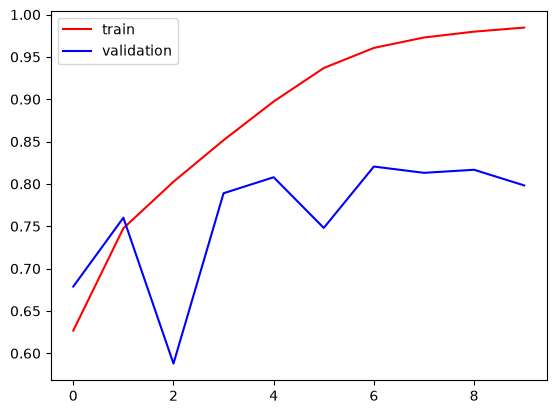

In [20]:
plt.plot(history.history['accuracy'], color = 'red', label = 'train')
plt.plot(history.history['val_accuracy'], color= 'blue', label = 'validation')
plt.legend()
plt.show()